# 01 — Exploração do fenótipo e teste de viés de base

**Objetivo:** juntar ABIDE I e II (TEA + controles) e ADHD-200 (TDAH + controles) numa tabela comum e verificar
se as features que as duas bases compartilham **identificam a base de origem** mesmo entre controles.

Se um classificador separa *controles ABIDE* de *controles ADHD-200*, qualquer modelo TEA × TDAH pode estar
aprendendo a base, e não o transtorno.

A tabela harmonizada é gerada por `src/harmonize.py`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from harmonize import harmonize

RANDOM_STATE = 42
FIG = ROOT / "results" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")

df = harmonize()
df.to_csv(ROOT / "data" / "interim" / "phenotype_harmonized.csv", index=False)
print(df.shape)
pd.crosstab(df["dataset"], df["diagnosis"], margins=True)

(2945, 15)


diagnosis,Controle,TDAH,TEA,All
dataset,,,,
ABIDE,1098,0,1013,2111
ADHD200,475,359,0,834
All,1573,359,1013,2945


## 1. Sujeitos por instituição
Instituições presentes nas duas famílias de bases (ABIDE e ADHD-200) são as mais úteis para separar efeito de diagnóstico de efeito de sítio. A coluna `institution` junta coortes da mesma instituição (ex.: NYU do ABIDE I, ABIDE II e ADHD-200).

In [2]:
print(pd.crosstab(df["release"], df["diagnosis"], margins=True))
por_inst = pd.crosstab([df["institution"]], [df["release"], df["diagnosis"]])
compartilhados = sorted(set(df.loc[df.dataset == "ABIDE", "institution"]) & set(df.loc[df.dataset == "ADHD200", "institution"]))
print("Instituições nas duas famílias:", compartilhados)
por_inst.loc[compartilhados]

diagnosis  Controle  TDAH   TEA   All
release                              
ABIDE_I         573     0   539  1112
ABIDE_II        525     0   474   999
ADHD200         475   359     0   834
All            1573   359  1013  2945
Instituições nas duas famílias: ['KKI', 'NYU', 'OHSU', 'Pittsburgh']


release      ABIDE_I     ABIDE_II      ADHD200     
diagnosis   Controle TEA Controle TEA Controle TDAH
institution                                        
KKI               33  22      147  56       13   22
NYU              105  79       30  75       58  152
OHSU              15  13       56  37       70   43
Pittsburgh        27  30        0   0       94    4

### Sujeitos repetidos
`harmonize()` já remove dois tipos de repetição:
- **Dentro do ADHD-200:** o `participants.tsv` do NYU lista ~100 sujeitos duas vezes.
- **Entre as bases:** controles do NYU e do KKI aparecem em mais de uma release (ABIDE I, ABIDE II, ADHD-200).
  Critério em `cross_dataset_duplicates`. Fica a cópia da release mais antiga (ABIDE I > ABIDE II > ADHD-200);
  se os diagnósticos divergissem, sairiam todas as cópias.

A célula abaixo mostra o que foi removido, a partir das tabelas brutas.

In [3]:
from harmonize import INSTITUTION, cross_dataset_duplicates, load_abide, load_abide2, load_adhd200

bruto = pd.concat([load_abide(), load_abide2(), load_adhd200()], ignore_index=True)
bruto = bruto[bruto.diagnosis.notna()].copy()
bruto["institution"] = bruto.pop("_cohort").fillna(bruto["site"]).replace(INSTITUTION).replace(INSTITUTION)
dup = cross_dataset_duplicates(bruto.drop(columns="_ctrl_adhd"))
print(f"Pares da mesma pessoa em releases diferentes: {len(dup)}")
pd.crosstab([dup.release_a, dup.release_b, dup.institution], [dup.diagnosis_a, dup.diagnosis_b])

Pares da mesma pessoa em releases diferentes: 109


diagnosis_a                     Controle
diagnosis_b                     Controle
release_a release_b institution         
ABIDE_I   ABIDE_II  KKI                8
          ADHD200   KKI                4
                    NYU               53
ABIDE_II  ADHD200   KKI               44

## 2. Idade, sexo e QI por grupo

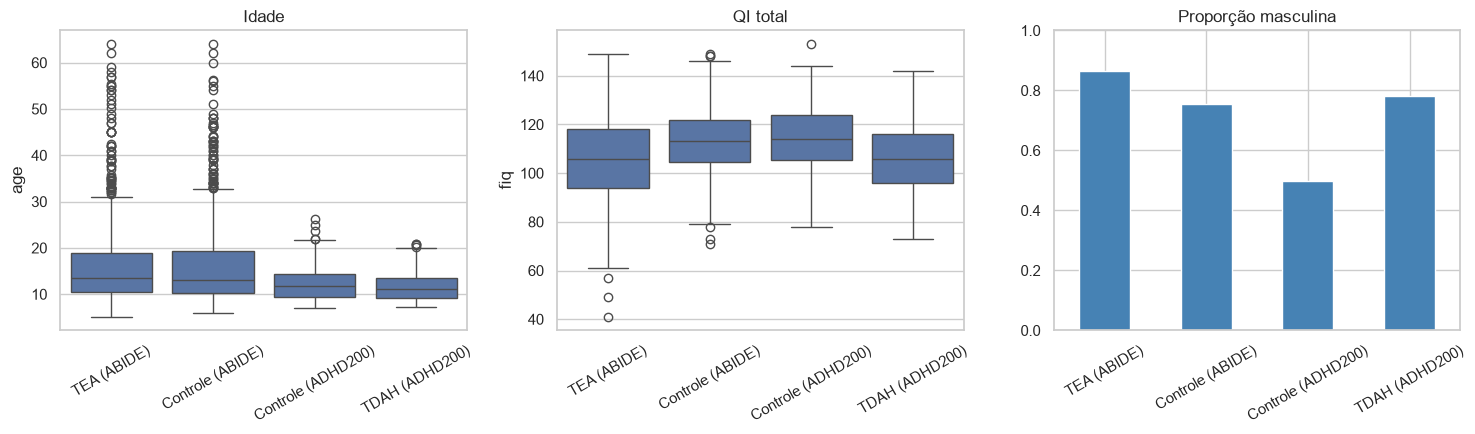

In [4]:
df["grupo"] = df["diagnosis"] + " (" + df["dataset"] + ")"
ordem = ["TEA (ABIDE)", "Controle (ABIDE)", "Controle (ADHD200)", "TDAH (ADHD200)"]
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
sns.boxplot(data=df, x="grupo", y="age", order=ordem, ax=ax[0]); ax[0].set_title("Idade")
sns.boxplot(data=df, x="grupo", y="fiq", order=ordem, ax=ax[1]); ax[1].set_title("QI total")
(df.groupby("grupo")["sex"].apply(lambda s: (s == "M").mean()).reindex(ordem)
   .plot.bar(ax=ax[2], color="steelblue")); ax[2].set_title("Proporção masculina"); ax[2].set_ylim(0, 1)
for a in ax:
    a.set_xlabel(""); a.tick_params(axis="x", rotation=30)
fig.tight_layout(); fig.savefig(FIG / "01_demografia_por_grupo.png", dpi=150)

In [5]:
df.groupby("grupo").agg(
    n=("subject_id", "size"), idade_media=("age", "mean"), idade_min=("age", "min"), idade_max=("age", "max"),
    masc=("sex", lambda s: (s == "M").mean()), fiq_media=("fiq", "mean"), fiq_ausente=("fiq", lambda s: s.isna().mean()),
).reindex(ordem).round(2)

,n,idade_media,idade_min,idade_max,masc,fiq_media,fiq_ausente
grupo,,,,,,,
TEA (ABIDE),1013,16.02,5.13,64.00,0.86,105.87,0.07
Controle (ABIDE),1098,16.06,5.89,64.00,0.75,112.91,0.09
Controle (ADHD200),475,12.39,7.09,26.31,0.50,113.76,0.07
TDAH (ADHD200),359,11.63,7.24,20.89,0.78,105.88,0.08


## 3. Coorte de análise
- Idade entre 7 e 21 anos, para as duas bases cobrirem a mesma faixa.
- TEA com TDAH comórbido registrado (`adhd_comorbid`) fica fora, para não misturar rótulos.

In [6]:
coorte = df[df.age.between(7, 21) & (df.adhd_comorbid == 0)].copy()
coorte.to_csv(ROOT / "data" / "interim" / "cohort_7_21.csv", index=False)
print(f"{len(df)} -> {len(coorte)} sujeitos")
pd.crosstab(coorte["dataset"], coorte["diagnosis"], margins=True)

2945 -> 2374 sujeitos


diagnosis,Controle,TDAH,TEA,All
dataset,,,,
ABIDE,868,0,682,1550
ADHD200,465,359,0,824
All,1333,359,682,2374


## 4. Teste de viés: o modelo reconhece a base só olhando os controles?

Usamos apenas controles e as features comuns (idade, sexo, QI, lateralidade). Alvo = base de origem.
- **Validação por instituição** (`StratifiedGroupKFold`, grupos = instituição): as instituições do teste nunca aparecem no treino.
- **Referência:** classificador que chuta a classe majoritária (acurácia balanceada = 0,5).

Acurácia balanceada perto de 0,5 = as features comuns não denunciam a base. Bem acima disso = viés.

In [7]:
FEATS = ["age", "sex_m", "fiq", "hand_right"]

def preparar(d):
    X = d.assign(sex_m=(d.sex == "M").astype(float))[FEATS].astype(float)
    return X

def teste_base(d, nome, por_sitio=True):
    ctrl = d[d.diagnosis == "Controle"]
    X, y, g = preparar(ctrl), (ctrl.dataset == "ABIDE").astype(int), ctrl.institution
    modelo = make_pipeline(SimpleImputer(strategy="median"),
                           RandomForestClassifier(n_estimators=500, min_samples_leaf=5,
                                                  class_weight="balanced", random_state=RANDOM_STATE))
    if por_sitio:
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
        kw = dict(groups=g)
    else:
        cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
        kw = {}
    s = cross_val_score(modelo, X, y, cv=cv, scoring="balanced_accuracy", **kw)
    s0 = cross_val_score(DummyClassifier(), X, y, cv=cv, scoring="balanced_accuracy", **kw)
    return {"cenário": nome, "n_controles": len(ctrl), "acc_bal_média": s.mean(), "acc_bal_dp": s.std(), "dummy": s0.mean()}

resultados = pd.DataFrame([
    teste_base(df, "Todas as idades, validação por instituição"),
    teste_base(coorte, "7–21 anos, validação por instituição"),
    teste_base(coorte[coorte.institution.isin(compartilhados)], "7–21 anos, só instituições compartilhadas", por_sitio=False),
]).round(3)
resultados

,cenário,n_controles,acc_bal_média,acc_bal_dp,dummy
0,"Todas as idades, validação por instituição",1573,0.604,0.076,0.5
1,"7–21 anos, validação por instituição",1333,0.545,0.067,0.5
2,"7–21 anos, só instituições compartilhadas",610,0.640,0.043,0.5


### Qual feature mais denuncia a base?
Importância por permutação no modelo treinado com a coorte 7–21 anos.

hand_right    0.011
fiq           0.039
age           0.060
sex_m         0.096
dtype: float64

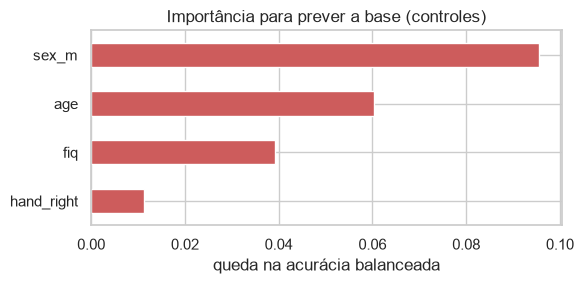

In [8]:
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

ctrl = coorte[coorte.diagnosis == "Controle"]
X, y = preparar(ctrl), (ctrl.dataset == "ABIDE").astype(int)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE)
m = make_pipeline(SimpleImputer(strategy="median"),
                  RandomForestClassifier(n_estimators=500, min_samples_leaf=5, class_weight="balanced",
                                         random_state=RANDOM_STATE)).fit(Xtr, ytr)
pi = permutation_importance(m, Xte, yte, scoring="balanced_accuracy", n_repeats=30, random_state=RANDOM_STATE)
imp = pd.Series(pi.importances_mean, index=FEATS).sort_values()
ax = imp.plot.barh(color="indianred", figsize=(6, 3)); ax.set_title("Importância para prever a base (controles)")
ax.set_xlabel("queda na acurácia balanceada"); plt.tight_layout(); plt.savefig(FIG / "01_importancia_vies_base.png", dpi=150)
imp.round(3)

## 5. Leitura dos resultados (execução de 25/11/2026, com ABIDE II)

- **Tabela harmonizada:** 2945 sujeitos únicos (1013 TEA, 359 TDAH, 1573 controles) de ABIDE I, ABIDE II e ADHD-200.
  109 controles apareciam em duas releases (NYU e KKI) e ficaram uma vez só. Nenhum par repetido tinha diagnóstico divergente.
- **Há viés de base mesmo entre controles.** Com idade, sexo, QI e lateralidade, o modelo acerta a família de base com
  acurácia balanceada de **0,55** na coorte 7–21 anos (validação por instituição; acaso = 0,50), 0,60 com todas as idades
  e 0,64 dentro das 4 instituições compartilhadas.
- **Sexo e idade são os principais responsáveis:** controles do ADHD-200 são 50% masculinos, contra 75% nos controles do ABIDE.
- **Coorte 7–21 anos sem TEA+TDAH:** 2374 sujeitos (682 TEA, 359 TDAH, 1333 controles). Os 141 TEA com TDAH comórbido
  ficam fora, mas continuam na tabela harmonizada para análises dos casos confundíveis.

**Próximo passo:** parear por sexo e idade (notebook 02).